In [41]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
from datetime import datetime
from scipy.optimize import curve_fit
from scipy import stats
from sklearn.model_selection import KFold
import warnings

import geostatspy.geostats as geostats
import geostatspy.GSLIB as GSLIB

plt.style.use('default')
pd.set_option('display.max_columns', None)
warnings.filterwarnings('ignore')

In [42]:
# --- Section 1: Enhanced Data Processing ---

def process_data(file, output_path=None):
    """Process rainfall data with proper temporal aggregation"""
    df_insitu_prec = file.copy()
    df_insitu_prec['date'] = pd.to_datetime(df_insitu_prec[['year', 'month', 'day']])
    
    # Extract Station Metadata
    df_station = df_insitu_prec[['index_no', 'lat', 'long']].drop_duplicates().reset_index(drop=True)
    
    # Define Seasons
    seasons = {
        'winter': [12, 1, 2],
        'pre_monsoon': [3, 4, 5],
        'monsoon': [6, 7, 8, 9],
        'post_monsoon': [10, 11]
    }

    # Map Seasons
    df_seasonal = df_insitu_prec.copy()
    df_seasonal['season'] = df_seasonal['month'].map(
        lambda x: [k for k, v in seasons.items() if x in v][0]
    )
    df_seasonal = df_seasonal[['index_no', 'lat', 'long', 'rainfall_sum', 'date', 'season']]
    df_seasonal['year'] = df_seasonal['date'].dt.year
    df_seasonal['month'] = df_seasonal['date'].dt.month

    # Adjust Year for Winter
    df_seasonal['year_seasonal'] = df_seasonal['year']
    df_seasonal.loc[df_seasonal['month'] == 12, 'year_seasonal'] = \
        df_seasonal.loc[df_seasonal['month'] == 12, 'year'] + 1

    # Aggregate Data
    df_seasonal_sum = df_seasonal.groupby(
        by=['index_no', 'season', 'year_seasonal']
    )[['rainfall_sum']].sum().reset_index()
    
    df_seasonal_averaged = df_seasonal_sum.groupby(
        by=['season', 'index_no']
    )[['rainfall_sum']].mean().reset_index()
    df_seasonal_averaged = df_seasonal_averaged.round(2)

    if output_path:
        df_seasonal_averaged.to_csv(output_path, index=False)

    # Merge Coordinates
    df_final = pd.merge(df_seasonal_averaged, df_station, on='index_no', how='left')
    df_final = df_final[['index_no', 'lat', 'long', 'season', 'rainfall_sum']]
    
    return df_final

In [43]:
# --- Section 2: Data Transformation Functions ---

def check_normality(data, name='Data'):
    """Comprehensive normality check with multiple tests"""
    print(f"\n{'='*50}")
    print(f"NORMALITY ANALYSIS: {name}")
    print(f"{'='*50}")
    
    clean_data = data[np.isfinite(data)]
    
    if len(clean_data) < 3:
        print("⚠ Insufficient data for normality testing")
        return None, None
    
    print(f"Mean: {np.mean(clean_data):.4f}")
    print(f"Std Dev: {np.std(clean_data):.4f}")
    print(f"Skewness: {stats.skew(clean_data):.4f}")
    print(f"Kurtosis: {stats.kurtosis(clean_data):.4f}")
    
    # Normality tests
    if len(clean_data) < 5000:
        _, shapiro_p = stats.shapiro(clean_data)
        print(f"\nShapiro-Wilk p-value: {shapiro_p:.4f}")
    else:
        shapiro_p = None
        print("\nShapiro-Wilk skipped (n > 5000)")
    
    _, ks_p = stats.kstest(clean_data, 'norm', args=(np.mean(clean_data), np.std(clean_data)))
    print(f"Kolmogorov-Smirnov p-value: {ks_p:.4f}")
    
    if shapiro_p and shapiro_p < 0.05:
        print("⚠ Data significantly deviates from normality (p<0.05)")
        print("→ Transformation recommended for optimal kriging")
    elif shapiro_p:
        print("✓ Data approximately normal")
    
    return shapiro_p, stats.skew(clean_data)

def apply_transformations(data):
    """Apply multiple transformations and evaluate which is best"""
    transformations = {}
    
    # Original
    transformations['original'] = {
        'data': data,
        'name': 'Original',
        'inverse': lambda x: x
    }
    
    # Box-Cox (handles positive data)
    if np.all(data > 0):
        try:
            bc_data, bc_lambda = stats.boxcox(data)
            transformations['boxcox'] = {
                'data': bc_data,
                'name': f'Box-Cox (λ={bc_lambda:.3f})',
                'lambda': bc_lambda,
                'inverse': lambda x: stats.inv_boxcox(x, bc_lambda)
            }
        except:
            pass
    
    # Log transform
    log_data = np.log(data + 0.01)
    transformations['log'] = {
        'data': log_data,
        'name': 'Log(x+0.01)',
        'inverse': lambda x: np.exp(x) - 0.01
    }
    
    # Square root
    sqrt_data = np.sqrt(data)
    transformations['sqrt'] = {
        'data': sqrt_data,
        'name': 'Square Root',
        'inverse': lambda x: x**2
    }
    
    # Fourth root
    fourth_data = data**(1/4)
    transformations['fourth_root'] = {
        'data': fourth_data,
        'name': 'Fourth Root',
        'inverse': lambda x: x**4
    }
    
    # Normal score
    try:
        ns_data, _, _ = geostats.nscore(pd.DataFrame({'val': data}), 'val')
        transformations['nscore'] = {
            'data': ns_data,
            'name': 'Normal Score',
            'inverse': None
        }
    except:
        pass
    
    # Evaluate each transformation
    results = []
    for key, trans in transformations.items():
        clean = trans['data'][np.isfinite(trans['data'])]
        if len(clean) > 3:
            try:
                _, shapiro_p = stats.shapiro(clean) if len(clean) < 5000 else (None, 0.5)
                skewness = stats.skew(clean)
                results.append({
                    'method': key,
                    'name': trans['name'],
                    'shapiro_p': shapiro_p if shapiro_p else 0.5,
                    'skewness': abs(skewness),
                    'data': trans['data'],
                    'inverse': trans.get('inverse')
                })
            except:
                continue
    
    if not results:
        # Fallback to original
        return pd.DataFrame([{
            'method': 'original',
            'name': 'Original',
            'shapiro_p': 0.5,
            'skewness': 0,
            'data': data,
            'inverse': lambda x: x
        }])
    
    return pd.DataFrame(results).sort_values('shapiro_p', ascending=False)

In [44]:
# --- Section 3: Enhanced Variogram Model Functions ---

def gaussian_model(h, nugget, psill, range_val):
    """Gaussian variogram model"""
    return nugget + psill * (1 - np.exp(-(h / range_val)**2))

def spherical_model(h, nugget, psill, range_val):
    """Spherical variogram model"""
    val = np.zeros_like(h, dtype=float)
    idx = h <= range_val
    val[idx] = nugget + psill * (1.5 * (h[idx]/range_val) - 0.5 * (h[idx]/range_val)**3)
    val[~idx] = nugget + psill
    return val

def exponential_model(h, nugget, psill, range_val):
    """Exponential variogram model"""
    return nugget + psill * (1 - np.exp(-3 * h / range_val))

def prepare_wls_weights_cressie(lag, gamma, n_pairs):
    """Prepare weights using Cressie (1985) method: N(h) / h²"""
    # Clean data
    valid = np.isfinite(gamma) & np.isfinite(lag) & np.isfinite(n_pairs)
    lag_c = lag[valid]
    gamma_c = gamma[valid]
    n_pairs_c = n_pairs[valid]
    
    # Remove zero lag
    mask = lag_c > 0
    lag_c, gamma_c, n_pairs_c = lag_c[mask], gamma_c[mask], n_pairs_c[mask]
    
    if len(lag_c) == 0:
        return np.array([]), np.array([]), np.array([])
    
    # Cressie weights: N(h) / h²
    weights = n_pairs_c / (lag_c**2)
    weights[~np.isfinite(weights)] = 1.0
    
    # Normalize weights
    weights = weights / np.sum(weights) * len(weights)
    
    # Return sigma for curve_fit
    sigma = 1.0 / np.sqrt(weights)
    
    return lag_c, gamma_c, sigma

def fit_variogram_model(model_func, lag_c, gamma_c, sigma, sample_var=None):
    """
    Fit variogram model with improved initial parameters and constraints
    FIXED: Better bounds and initial guess logic
    """
    if len(lag_c) < 3:
        return None
    
    # Estimate initial parameters from data
    max_gamma = np.max(gamma_c)
    max_lag = np.max(lag_c)
    mean_gamma = np.mean(gamma_c)
    
    # Better initial estimates
    # Nugget: start small
    nugget_init = min(gamma_c[0] if len(gamma_c) > 0 else 0, max_gamma * 0.1)
    
    # Partial sill: based on data
    if sample_var is not None:
        # Use sample variance as guide
        psill_init = max(0.1, min(sample_var * 0.8, max_gamma * 0.9))
    else:
        psill_init = max(0.1, max_gamma * 0.7)
    
    # Range: between 1/3 and 2/3 of max lag
    range_init = max_lag / 2
    
    p0 = [nugget_init, psill_init, range_init]
    
    # Set flexible bounds
    if sample_var is not None and sample_var > 0:
        # Allow flexibility around sample variance
        max_sill = sample_var * 2.0
    else:
        max_sill = max_gamma * 2.0
    
    bounds = (
        [0, 0, max_lag * 0.01],  # Lower bounds: nugget≥0, psill≥0, range≥1% of max_lag
        [max_sill * 0.5, max_sill * 1.5, max_lag * 3]  # Upper bounds: flexible
    )
    
    # Ensure p0 is within bounds
    p0[0] = np.clip(p0[0], bounds[0][0], bounds[1][0])
    p0[1] = np.clip(p0[1], bounds[0][1], bounds[1][1])
    p0[2] = np.clip(p0[2], bounds[0][2], bounds[1][2])
    
    try:
        popt, pcov = curve_fit(
            model_func, lag_c, gamma_c, p0=p0,
            bounds=bounds, sigma=sigma, 
            absolute_sigma=True, maxfev=10000
        )
        
        # Calculate goodness of fit metrics
        fitted = model_func(lag_c, *popt)
        residuals = gamma_c - fitted
        weights = 1 / sigma**2
        
        wrss = np.sum(weights * residuals**2)
        rmse = np.sqrt(np.mean(residuals**2))
        
        # R²
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((gamma_c - np.mean(gamma_c))**2)
        r_squared = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0
        
        # Parameter errors
        perr = np.sqrt(np.diag(pcov))
        
        return {
            'params': popt,
            'rmse': rmse,
            'wrss': wrss,
            'r_squared': r_squared,
            'param_errors': perr
        }
    except Exception as e:
        print(f"  Fitting failed: {e}")
        return None

In [45]:
# --- Section 4: Automatic Lag Parameter Optimization ---

def calculate_optimal_lag_params(df_subset):
    """Calculate optimal lag parameters based on data characteristics"""
    coords = df_subset[['lat', 'long']].values
    
    # Calculate all pairwise distances
    from scipy.spatial.distance import pdist, squareform
    distances = squareform(pdist(coords, metric='euclidean'))
    
    # Get upper triangle
    upper_tri = np.triu_indices_from(distances, k=1)
    all_distances = distances[upper_tri]
    all_distances = all_distances[all_distances > 0]
    
    if len(all_distances) == 0:
        return 0.1, 0.05, 10
    
    # Statistics
    min_dist = np.min(all_distances)
    max_dist = np.max(all_distances)
    median_dist = np.median(all_distances)
    
    # Optimal lag distance: approximately half the minimum spacing
    lag_dist = max(min_dist / 2, 0.01)
    
    # Lag tolerance: half of lag distance
    lag_tol = lag_dist / 2
    
    # Number of lags: to cover about half the maximum distance
    effective_range = max_dist / 2
    n_lag = int(effective_range / lag_dist)
    n_lag = max(10, min(n_lag, 25))
    
    print(f"\nDistance Statistics:")
    print(f"  Min distance: {min_dist:.4f}°")
    print(f"  Max distance: {max_dist:.4f}°")
    print(f"  Median distance: {median_dist:.4f}°")
    print(f"\nOptimized Parameters:")
    print(f"  Lag distance: {lag_dist:.4f}°")
    print(f"  Lag tolerance: {lag_tol:.4f}°")
    print(f"  Number of lags: {n_lag}")
    print(f"  Effective range coverage: {effective_range:.4f}°")
    
    return lag_dist, lag_tol, n_lag

In [46]:
# --- Section 5: Cross-Validation ---

def cross_validate_variogram(df_subset, model_func, params, n_splits=5):
    """K-fold cross-validation for variogram model"""
    if len(df_subset) < n_splits:
        n_splits = max(2, len(df_subset) // 2)
    
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    mae_scores = []
    rmse_scores = []
    
    for train_idx, test_idx in kf.split(df_subset):
        train_data = df_subset.iloc[train_idx]
        test_data = df_subset.iloc[test_idx]
        
        for _, test_point in test_data.iterrows():
            test_coords = np.array([test_point['lat'], test_point['long']])
            
            # Calculate distances to training points
            train_coords = train_data[['lat', 'long']].values
            distances = np.sqrt(
                (train_coords[:, 0] - test_coords[0])**2 + 
                (train_coords[:, 1] - test_coords[1])**2
            )
            
            # Use variogram for weights
            nugget, psill, range_val = params
            gamma_values = model_func(distances, nugget, psill, range_val)
            
            gamma_values = np.where(gamma_values < 1e-6, 1e-6, gamma_values)
            weights = 1 / gamma_values
            weights = weights / np.sum(weights)
            
            # Prediction
            predicted = np.sum(weights * train_data['transformed'].values)
            actual = test_point['transformed']
            
            mae_scores.append(np.abs(predicted - actual))
            rmse_scores.append((predicted - actual)**2)
    
    mae = np.mean(mae_scores) if mae_scores else 999
    rmse = np.sqrt(np.mean(rmse_scores)) if rmse_scores else 999
    
    return {'MAE': mae, 'RMSE': rmse}

In [47]:
# --- Section 6: Comprehensive Seasonal Analysis ---

def perform_comprehensive_analysis(df_input, season_name):
    """Complete variogram analysis pipeline with all best practices"""
    print(f"\n{'='*70}")
    print(f"COMPREHENSIVE VARIOGRAM ANALYSIS: {season_name.upper()}")
    print(f"{'='*70}")
    
    # 1. Filter and prepare data
    df_subset = df_input[df_input['season'] == season_name].copy()
    n_stations = len(df_subset)
    print(f"\nNumber of stations: {n_stations}")
    
    if n_stations < 30:
        print("⚠ WARNING: Less than 30 stations. Results may be unreliable.")
    
    # 2. Data exploration and transformation
    print(f"\n{'-'*70}")
    print("STEP 1: DATA TRANSFORMATION ANALYSIS")
    print(f"{'-'*70}")
    
    original_data = df_subset['rainfall_sum'].values
    
    # Check normality
    shapiro_p, skewness = check_normality(original_data, 'Original Rainfall')
    
    # Try transformations
    trans_results = apply_transformations(original_data)
    print(f"\nTransformation Comparison:")
    print(trans_results[['method', 'name', 'shapiro_p', 'skewness']].to_string(index=False))
    
    # Select best transformation
    best_trans = trans_results.iloc[0]
    print(f"\n✓ Best transformation: {best_trans['name']}")
    
    # Apply transformation
    df_subset['transformed'] = best_trans['data']
    inverse_func = best_trans['inverse']
    
    # 3. Visualizations
    print(f"\n{'-'*70}")
    print("STEP 2: DATA VISUALIZATION")
    print(f"{'-'*70}")
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Original histogram
    axes[0,0].hist(original_data, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    axes[0,0].set_title(f'Original Rainfall - {season_name}')
    axes[0,0].set_xlabel('Rainfall (mm)')
    axes[0,0].axvline(np.mean(original_data), color='red', linestyle='--', 
                      label=f'Mean: {np.mean(original_data):.1f}')
    axes[0,0].legend()
    
    # Transformed histogram
    axes[0,1].hist(df_subset['transformed'], bins=30, color='salmon', 
                   edgecolor='black', alpha=0.7)
    axes[0,1].set_title(f'Transformed - {best_trans["name"]}')
    axes[0,1].set_xlabel('Transformed Value')
    
    # Q-Q plots
    stats.probplot(original_data, dist="norm", plot=axes[0,2])
    axes[0,2].set_title('Q-Q: Original')
    
    stats.probplot(df_subset['transformed'].values, dist="norm", plot=axes[1,0])
    axes[1,0].set_title(f'Q-Q: {best_trans["name"]}')
    
    # Spatial map
    sc = axes[1,1].scatter(df_subset['lat'], df_subset['long'], 
                          c=df_subset['transformed'], cmap='viridis',
                          s=50, edgecolors='k', linewidth=0.5)
    axes[1,1].set_title('Station Locations')
    axes[1,1].set_xlabel('Latitude')
    axes[1,1].set_ylabel('Longitude')
    plt.colorbar(sc, ax=axes[1,1], label='Transformed')
    
    axes[1,2].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # 4. Calculate optimal lag parameters
    print(f"\n{'-'*70}")
    print("STEP 3: LAG PARAMETER OPTIMIZATION")
    print(f"{'-'*70}")
    
    lag_dist, lag_tol, nlag = calculate_optimal_lag_params(df_subset)
    
    # 5. Compute experimental variogram
    print(f"\n{'-'*70}")
    print("STEP 4: EXPERIMENTAL VARIOGRAM")
    print(f"{'-'*70}")
    
    tmin, tmax = -9999, 9999
    bandh = 9999.9
    azi, atol = 0, 90
    isill = 1
    
    lag_exp, gamma_exp, n_pairs = geostats.gamv(
        df_subset, 'lat', 'long', 'transformed',
        tmin, tmax, lag_dist, lag_tol, nlag, 
        azi, atol, bandh, isill
    )
    
    valid_lags = np.sum(np.isfinite(gamma_exp))
    print(f"Experimental variogram computed:")
    print(f"  Valid lag bins: {valid_lags}")
    
    if valid_lags < 3:
        print("⚠ ERROR: Not enough valid lag bins for fitting")
        return None
    
    # Plot experimental
    plt.figure(figsize=(10, 6))
    valid = np.isfinite(gamma_exp) & np.isfinite(lag_exp)
    plt.plot(lag_exp[valid], gamma_exp[valid], 'o', color='black', 
             markersize=8, label='Experimental', zorder=10)
    
    sample_var = np.var(df_subset['transformed'].values)
    plt.axhline(y=sample_var, color='green', linestyle='--', 
                label=f'Sample Variance: {sample_var:.3f}', linewidth=2)
    
    plt.xlabel('Lag Distance (degrees)', fontsize=12)
    plt.ylabel('Semivariance', fontsize=12)
    plt.title(f'Experimental Variogram - {season_name}', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.show()
    
    # 6. Fit variogram models
    print(f"\n{'-'*70}")
    print("STEP 5: VARIOGRAM MODEL FITTING")
    print(f"{'-'*70}")
    
    lag_c, gamma_c, sigma = prepare_wls_weights_cressie(lag_exp, gamma_exp, n_pairs)
    
    if len(lag_c) == 0:
        print("ERROR: No valid lag-gamma pairs for fitting")
        return None
    
    print(f"Fitting with {len(lag_c)} lag bins using Cressie (1985) weights")
    print(f"Sample variance: {sample_var:.4f}")
    
    models = {
        'Gaussian': gaussian_model,
        'Spherical': spherical_model,
        'Exponential': exponential_model
    }
    
    colors = {'Gaussian': 'blue', 'Spherical': 'green', 'Exponential': 'red'}
    
    results_list = []
    
    print(f"\n{'Model':<12} {'Nugget':<10} {'PSill':<10} {'Range':<10} "
          f"{'Total Sill':<12} {'RMSE':<10} {'R²':<8}")
    print("-" * 85)
    
    for name, func in models.items():
        result = fit_variogram_model(func, lag_c, gamma_c, sigma, sample_var)
        
        if result is not None:
            nugget, psill, range_val = result['params']
            total_sill = nugget + psill
            nugget_ratio = nugget / total_sill if total_sill > 0 else 0
            
            print(f"{name:<12} {nugget:<10.4f} {psill:<10.4f} {range_val:<10.4f} "
                  f"{total_sill:<12.4f} {result['rmse']:<10.4f} {result['r_squared']:<8.4f}")
            
            # Cross-validation
            try:
                cv_results = cross_validate_variogram(df_subset, func, result['params'])
            except:
                cv_results = {'MAE': 999, 'RMSE': 999}
            
            results_list.append({
                'model': name,
                'nugget': nugget,
                'psill': psill,
                'range': range_val,
                'total_sill': total_sill,
                'nugget_ratio': nugget_ratio,
                'rmse': result['rmse'],
                'wrss': result['wrss'],
                'r_squared': result['r_squared'],
                'cv_mae': cv_results['MAE'],
                'cv_rmse': cv_results['RMSE'],
                'function': func,
                'params': result['params']
            })
        else:
            print(f"{name:<12} {'Fit Failed'}")
    
    if not results_list:
        print("⚠ ERROR: All models failed to fit")
        return None
    
    # 7. Model comparison plot
    print(f"\n{'-'*70}")
    print("STEP 6: MODEL COMPARISON")
    print(f"{'-'*70}")
    
    plt.figure(figsize=(12, 7))
    plt.scatter(lag_c, gamma_c, c='black', marker='o', s=80, 
                label='Experimental', zorder=10, edgecolors='white', linewidth=1.5)
    
    h_fit = np.linspace(0, max(lag_c) * 1.1, 200)
    
    for res in results_list:
        fitted_curve = res['function'](h_fit, *res['params'])
        plt.plot(h_fit, fitted_curve, color=colors[res['model']], 
                lw=2.5, label=f"{res['model']} (R²={res['r_squared']:.3f})", 
                alpha=0.8)
    
    plt.axhline(y=sample_var, color='green', linestyle='--', 
                label=f'Sample Variance: {sample_var:.3f}', linewidth=2)
    
    plt.xlabel('Lag Distance (degrees)', fontsize=12)
    plt.ylabel('Semivariance', fontsize=12)
    plt.title(f'Variogram Model Comparison - {season_name}', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    # 8. Select best model
    results_df = pd.DataFrame(results_list)
    
    print("\nModel Comparison:")
    print(results_df[['model', 'nugget', 'psill', 'range', 'nugget_ratio', 
                     'rmse', 'r_squared']].to_string(index=False))
    
    # Select: highest R² with reasonable nugget ratio
    results_df['score'] = results_df['r_squared'] * (1 - results_df['nugget_ratio'])
    best_model = results_df.loc[results_df['score'].idxmax()]
    
    print(f"\n{'='*70}")
    print(f"RECOMMENDED MODEL: {best_model['model']}")
    print(f"{'='*70}")
    print(f"  Nugget: {best_model['nugget']:.4f}")
    print(f"  Partial Sill: {best_model['psill']:.4f}")
    print(f"  Range: {best_model['range']:.4f}°")
    print(f"  Total Sill: {best_model['total_sill']:.4f}")
    print(f"  Nugget/Sill Ratio: {best_model['nugget_ratio']:.3f}")
    print(f"  R²: {best_model['r_squared']:.4f}")
    
    print(f"\nInterpretation:")
    if best_model['nugget_ratio'] < 0.25:
        print("  ✓ Strong spatial structure")
    elif best_model['nugget_ratio'] < 0.50:
        print("  ○ Moderate spatial structure")
    else:
        print("  ⚠ Weak spatial structure")
    
    print(f"  Effective range: ~{best_model['range'] * 111:.1f} km")
    
    return {
        'season': season_name,
        'transformation': best_trans['name'],
        'best_model': best_model,
        'all_results': results_df,
        'inverse_transform': inverse_func,
        'sample_var': sample_var,
        'lag_params': {'lag_dist': lag_dist, 'lag_tol': lag_tol, 'nlag': nlag}
    }

Data processing complete.
Total stations: 50
Seasons: ['monsoon' 'post_monsoon' 'pre_monsoon' 'winter']

COMPREHENSIVE VARIOGRAM ANALYSIS: WINTER

Number of stations: 50

----------------------------------------------------------------------
STEP 1: DATA TRANSFORMATION ANALYSIS
----------------------------------------------------------------------

NORMALITY ANALYSIS: Original Rainfall
Mean: 55.5160
Std Dev: 31.4567
Skewness: 1.0857
Kurtosis: 0.1747

Shapiro-Wilk p-value: 0.0000
Kolmogorov-Smirnov p-value: 0.0345
⚠ Data significantly deviates from normality (p<0.05)
→ Transformation recommended for optimal kriging

Transformation Comparison:
     method              name    shapiro_p  skewness
     boxcox Box-Cox (λ=0.015) 4.830833e-02  0.000397
        log       Log(x+0.01) 4.753653e-02  0.025153
fourth_root       Fourth Root 2.734925e-02  0.360926
       sqrt       Square Root 4.505439e-03  0.653937
   original          Original 4.598067e-05  1.085721
     nscore      Normal Score 2.

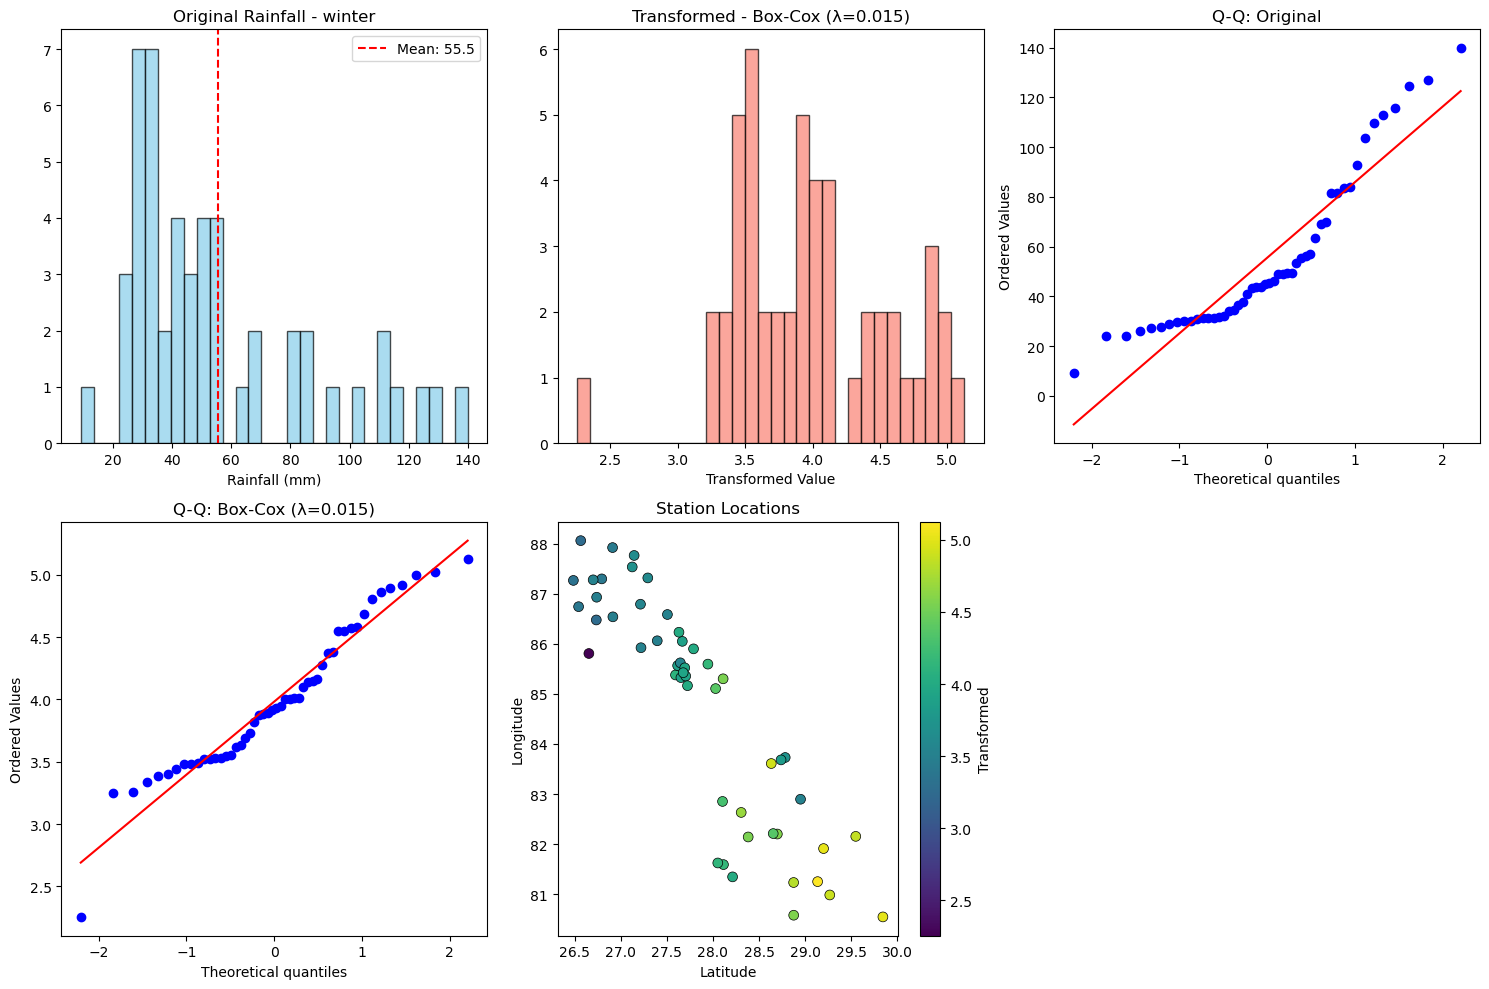


----------------------------------------------------------------------
STEP 3: LAG PARAMETER OPTIMIZATION
----------------------------------------------------------------------

Distance Statistics:
  Min distance: 0.0456°
  Max distance: 8.2011°
  Median distance: 2.3918°

Optimized Parameters:
  Lag distance: 0.0228°
  Lag tolerance: 0.0114°
  Number of lags: 25
  Effective range coverage: 4.1005°

----------------------------------------------------------------------
STEP 4: EXPERIMENTAL VARIOGRAM
----------------------------------------------------------------------
Experimental variogram computed:
  Valid lag bins: 27


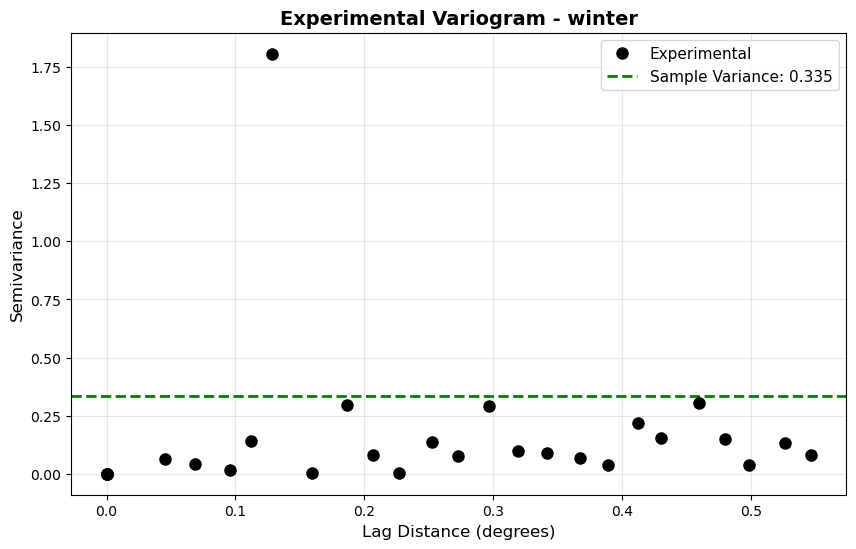


----------------------------------------------------------------------
STEP 5: VARIOGRAM MODEL FITTING
----------------------------------------------------------------------
Fitting with 23 lag bins using Cressie (1985) weights
Sample variance: 0.3354

Model        Nugget     PSill      Range      Total Sill   RMSE       R²      
-------------------------------------------------------------------------------------
Gaussian     0.0000     0.1822     0.0962     0.1822       0.3590     -0.0157 
Spherical    0.0000     0.1680     0.1939     0.1680       0.3594     -0.0178 
Exponential  0.0000     0.1791     0.3161     0.1791       0.3626     -0.0361 

----------------------------------------------------------------------
STEP 6: MODEL COMPARISON
----------------------------------------------------------------------


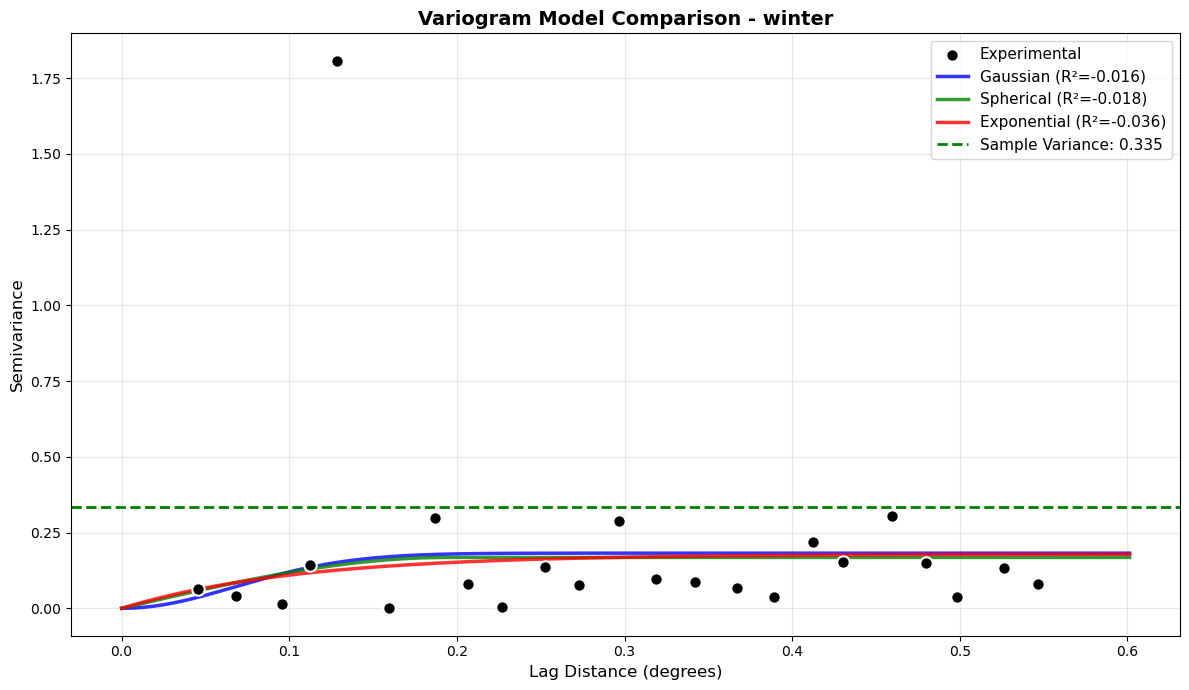


Model Comparison:
      model       nugget    psill    range  nugget_ratio     rmse  r_squared
   Gaussian 7.854394e-10 0.182174 0.096206  4.311470e-09 0.358986  -0.015656
  Spherical 3.100376e-15 0.167988 0.193909  1.845595e-14 0.359366  -0.017803
Exponential 1.052206e-25 0.179092 0.316062  5.875211e-25 0.362590  -0.036147

RECOMMENDED MODEL: Gaussian
  Nugget: 0.0000
  Partial Sill: 0.1822
  Range: 0.0962°
  Total Sill: 0.1822
  Nugget/Sill Ratio: 0.000
  R²: -0.0157

Interpretation:
  ✓ Strong spatial structure
  Effective range: ~10.7 km

FINAL SUMMARY: ALL SEASONS

Season    Transformation Best Model Nugget  PSill Range (°) Range (km) Nugget/Sill     R²
Winter Box-Cox (λ=0.015)   Gaussian 0.0000 0.1822    0.0962       10.7       0.000 -0.016

ANALYSIS COMPLETE - Ready for Ordinary Kriging



In [48]:
# --- Section 7: Execute Analysis ---

# Load data
insitu_total_df = pd.read_csv(r"..\Data\Processed\Insitu\insitu_rainfall_1991_2020.csv")

# Filter for training stations
train_stations_df = pd.read_csv(r"..\Data\Processed\Split_stations\train_stations.csv")
train_stations = train_stations_df['index_no'].tolist()
insitu_total_df = insitu_total_df[insitu_total_df['index_no'].isin(train_stations)]

# Process data
output_file = r"..\Data\Processed\Variogram_analysis\seasonal_averaged.csv"
df_all_seasons = process_data(insitu_total_df, output_file)

print("Data processing complete.")
print(f"Total stations: {df_all_seasons['index_no'].nunique()}")
print(f"Seasons: {df_all_seasons['season'].unique()}")

# %%
# Analyze all seasons
seasons_to_analyze = ['winter'] #, 'pre_monsoon', 'monsoon', 'post_monsoon']
all_season_results = {}

for season in seasons_to_analyze:
    result = perform_comprehensive_analysis(df_all_seasons, season)
    if result:
        all_season_results[season] = result

# %%
# --- Section 8: Summary Report ---

print(f"\n{'='*70}")
print("FINAL SUMMARY: ALL SEASONS")
print(f"{'='*70}\n")

if all_season_results:
    summary_data = []
    for season, result in all_season_results.items():
        bm = result['best_model']
        summary_data.append({
            'Season': season.capitalize(),
            'Transformation': result['transformation'],
            'Best Model': bm['model'],
            'Nugget': f"{bm['nugget']:.4f}",
            'PSill': f"{bm['psill']:.4f}",
            'Range (°)': f"{bm['range']:.4f}",
            'Range (km)': f"{bm['range'] * 111:.1f}",
            'Nugget/Sill': f"{bm['nugget_ratio']:.3f}",
            'R²': f"{bm['r_squared']:.3f}"
        })
    
    summary_df = pd.DataFrame(summary_data)
    print(summary_df.to_string(index=False))
    
    print(f"\n{'='*70}")
    print("ANALYSIS COMPLETE - Ready for Ordinary Kriging")
    print(f"{'='*70}\n")
else:
    print("⚠ No successful variogram fits. Check your data.")